# VinDr-CXR: U-Net Baseline

This notebook trains a small U-Net to reproduce **bounding-box-derived pseudo-masks** for the validated VinDr-CXR subset.

**Important limitation:** these are filled rectangles from radiologist bounding boxes, not pixel-level lesion segmentation masks. The model is learning to approximate the boxes, not true lesion boundaries. Treat the results as a pipeline prototype only.

## 1. Install dependencies

Run this cell once in the notebook's active project environment. Restart the kernel if packages were installed or upgraded.

In [1]:
%pip install torch torchvision pydicom pylibjpeg pylibjpeg-openjpeg pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Imports and project paths

The notebook expects the project structure to contain `data/processed/validated_manifest.csv` and `data/annotations/annotations_train.csv`.

In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
SIZE = 256
BATCH_SIZE = 4
EPOCHS = 10
LEARNING_RATE = 1e-3

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Find the project root, whether the notebook runs from the root or notebooks/
ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Could not find the project root. Open this notebook from "
            "the chest-xray-ai-annotation project."
        )
    ROOT = ROOT.parent

MANIFEST_PATH = ROOT / "data" / "processed" / "validated_manifest.csv"
ANNOTATIONS_PATH = ROOT / "data" / "annotations" / "annotations_train.csv"

manifest = pd.read_csv(MANIFEST_PATH, dtype={"image_id": str})
annotations = pd.read_csv(ANNOTATIONS_PATH, dtype={"image_id": str})

# Keep only images flagged as having bounding boxes.
# The manifest may read this column as bool or text depending on how it was saved.
has_bbox = manifest["has_bbox"].astype(str).str.lower().isin(["true", "1", "yes"])
sample = manifest.loc[has_bbox].drop_duplicates("image_id").reset_index(drop=True)

print("Project root:", ROOT)
print("Validated images in manifest:", manifest["image_id"].nunique())
print("Unique images with bounding boxes:", len(sample))
print("Device will be selected in the training section.")

Project root: c:\Users\johnm\chest-xray-ai-annotation
Validated images in manifest: 295
Unique images with bounding boxes: 100
Device will be selected in the training section.


## 3. Convert DICOMs and bounding boxes into model inputs

Each X-ray is resized to 256 × 256. Each bounding box is filled to create a binary pseudo-mask. Multiple radiologists' boxes are combined into one union mask for this baseline.

Images that fail to decode are skipped and reported.

In [3]:
def load_image_and_mask(row, size=SIZE):
    # Read and decode the original DICOM image.
    dicom_path = ROOT / row["dicom_path"]
    ds = pydicom.dcmread(str(dicom_path))
    image = ds.pixel_array.astype(np.float32)

    if image.ndim != 2:
        raise ValueError(f"Expected a 2D X-ray, got shape {image.shape}")

    # Robust intensity scaling helps reduce the influence of extreme pixels.
    lo, hi = np.percentile(image, [1, 99])
    if hi > lo:
        image = np.clip(image, lo, hi)
        image = (image - lo) / (hi - lo)
    else:
        image = np.zeros_like(image, dtype=np.float32)

    # Invert MONOCHROME1 images so the display convention is consistent.
    if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
        image = 1.0 - image

    original_h, original_w = image.shape

    # Resize the image to the fixed model input size.
    image_tensor = torch.from_numpy(image)[None, None]
    image = F.interpolate(
        image_tensor, size=(size, size),
        mode="bilinear", align_corners=False
    )[0, 0].numpy()

    # Create a binary mask by filling every valid box for this image.
    mask = np.zeros((size, size), dtype=np.float32)
    image_boxes = annotations[
        annotations["image_id"] == str(row["image_id"])
    ].dropna(subset=["x_min", "y_min", "x_max", "y_max"])

    for _, box in image_boxes.iterrows():
        x1 = int(np.floor(float(box["x_min"]) / original_w * size))
        x2 = int(np.ceil(float(box["x_max"]) / original_w * size))
        y1 = int(np.floor(float(box["y_min"]) / original_h * size))
        y2 = int(np.ceil(float(box["y_max"]) / original_h * size))

        # Clip coordinates to valid image bounds.
        x1, x2 = np.clip([x1, x2], 0, size)
        y1, y2 = np.clip([y1, y2], 0, size)

        if x2 > x1 and y2 > y1:
            mask[y1:y2, x1:x2] = 1.0

    return image.astype(np.float32), mask


images, masks, loaded_ids, failed_images = [], [], [], []

for _, row in sample.iterrows():
    try:
        image, mask = load_image_and_mask(row)
        images.append(image)
        masks.append(mask)
        loaded_ids.append(row["image_id"])
    except Exception as exc:
        failed_images.append((row["image_id"], str(exc)))

if not images:
    raise RuntimeError("No annotated images loaded successfully. Check the manifest paths.")

images = np.stack(images)
masks = np.stack(masks)

print("Images loaded:", len(images))
print("Image array shape:", images.shape)
print("Pseudo-mask array shape:", masks.shape)
print("Mean positive-mask fraction:", round(float(masks.mean()), 4))
print("Images skipped:", len(failed_images))
if failed_images:
    for image_id, reason in failed_images:
        print(f"  {image_id}: {reason}")

Images loaded: 100
Image array shape: (100, 256, 256)
Pseudo-mask array shape: (100, 256, 256)
Mean positive-mask fraction: 0.1233
Images skipped: 0


## 4. Inspect one input and its pseudo-mask

Check that the red regions align with the boxes. The mask intentionally contains full rectangles, including normal anatomy inside each box.

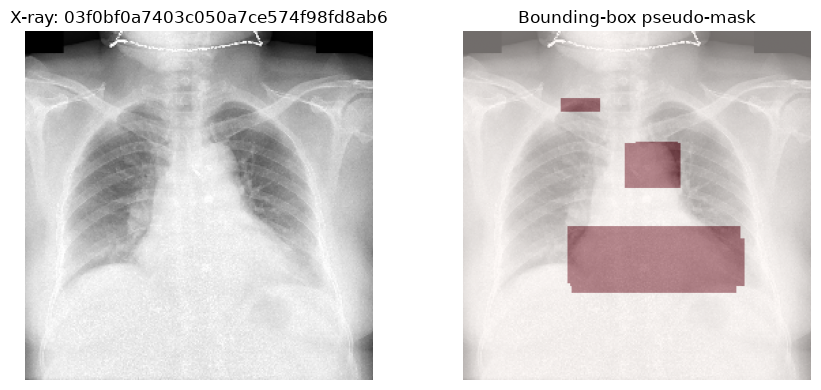

In [4]:
idx = 0

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(images[idx], cmap="gray")
ax[0].set_title(f"X-ray: {loaded_ids[idx]}")
ax[0].axis("off")

ax[1].imshow(images[idx], cmap="gray")
ax[1].imshow(masks[idx], cmap="Reds", alpha=0.45, vmin=0, vmax=1)
ax[1].set_title("Bounding-box pseudo-mask")
ax[1].axis("off")

plt.tight_layout()
plt.show()

## 5. Train/validation split and data loaders

The split is performed by image, so the same image cannot appear in both sets. The validation set is held out from gradient updates.

In [5]:
indices = np.arange(len(images))
if len(indices) < 5:
    raise ValueError("Need at least 5 successfully loaded annotated images for a train/validation split.")

train_idx, val_idx = train_test_split(
    indices, test_size=0.2, random_state=SEED
)

# Add the single-channel dimension expected by U-Net: (N, 1, H, W).
X = torch.from_numpy(images[:, None]).float()
Y = torch.from_numpy(masks[:, None]).float()

train_ds = TensorDataset(X[train_idx], Y[train_idx])
val_ds = TensorDataset(X[val_idx], Y[val_idx])

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    pin_memory=torch.cuda.is_available()
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Training images:", len(train_ds))
print("Validation images:", len(val_ds))

Device: cpu
Training images: 80
Validation images: 20


## 6. Define a small U-Net

The network takes one grayscale channel and returns one logit per pixel. A sigmoid is applied only when converting logits to probabilities for visualization or metrics.

In [6]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(1, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(64, 128)

        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec3 = conv_block(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec2 = conv_block(64, 32)
        self.up1 = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.dec1 = conv_block(32, 16)

        self.output_layer = nn.Conv2d(16, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.output_layer(d1)


model = UNet().to(device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

Trainable parameters: 481745


## 7. Loss function and optimizer

BCE handles per-pixel classification; Dice loss encourages overlap with the target mask. The combined loss is a training objective, not a clinical performance metric.

In [7]:
bce_loss = nn.BCEWithLogitsLoss()

def dice_loss(logits, targets, smooth=1.0):
    probabilities = torch.sigmoid(logits)
    probabilities = probabilities.flatten(start_dim=1)
    targets = targets.flatten(start_dim=1)

    intersection = (probabilities * targets).sum(dim=1)
    denominator = probabilities.sum(dim=1) + targets.sum(dim=1)
    dice = (2 * intersection + smooth) / (denominator + smooth)
    return 1.0 - dice.mean()


def combined_loss(logits, targets):
    return bce_loss(logits, targets) + dice_loss(logits, targets)


criterion = combined_loss
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

## 8. Train U-Net

This baseline runs for 10 epochs. Both losses are averaged per image. Training loss should generally trend down, but loss alone cannot prove that predictions are useful.

Epoch 01/10 | Train loss: 1.3628 | Val loss: 1.2972
Epoch 02/10 | Train loss: 1.2795 | Val loss: 1.2828
Epoch 03/10 | Train loss: 1.2653 | Val loss: 1.2862
Epoch 04/10 | Train loss: 1.2555 | Val loss: 1.2559
Epoch 05/10 | Train loss: 1.2577 | Val loss: 1.2750
Epoch 06/10 | Train loss: 1.2554 | Val loss: 1.2748
Epoch 07/10 | Train loss: 1.2430 | Val loss: 1.2450
Epoch 08/10 | Train loss: 1.2372 | Val loss: 1.2337
Epoch 09/10 | Train loss: 1.2334 | Val loss: 1.2229
Epoch 10/10 | Train loss: 1.2382 | Val loss: 1.2502


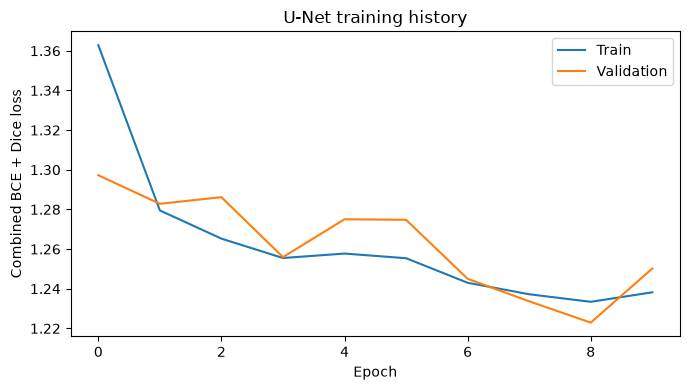

In [8]:
history = {"train_loss": [], "val_loss": []}

for epoch in range(EPOCHS):
    model.train()
    train_total = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        train_total += loss.item() * xb.size(0)

    model.eval()
    val_total = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            val_total += criterion(model(xb), yb).item() * xb.size(0)

    train_loss_value = train_total / len(train_ds)
    val_loss_value = val_total / len(val_ds)
    history["train_loss"].append(train_loss_value)
    history["val_loss"].append(val_loss_value)

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train loss: {train_loss_value:.4f} | "
        f"Val loss: {val_loss_value:.4f}"
    )

# Plot the training curves.
plt.figure(figsize=(7, 4))
plt.plot(history["train_loss"], label="Train")
plt.plot(history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Combined BCE + Dice loss")
plt.title("U-Net training history")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Evaluate on the held-out validation set

Dice and IoU are calculated against the box-derived pseudo-masks at a fixed threshold of 0.5. They measure agreement with these rectangles, not true lesion segmentation accuracy.

In [9]:
THRESHOLD = 0.5
dice_scores, iou_scores = [], []
model.eval()

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model(xb.to(device))
        predictions = (torch.sigmoid(logits) >= THRESHOLD).float()
        targets = yb.to(device)

        predictions = predictions.flatten(start_dim=1)
        targets = targets.flatten(start_dim=1)

        intersection = (predictions * targets).sum(dim=1)
        pred_area = predictions.sum(dim=1)
        target_area = targets.sum(dim=1)
        union = pred_area + target_area - intersection

        dice = (2 * intersection + 1e-7) / (pred_area + target_area + 1e-7)
        iou = (intersection + 1e-7) / (union + 1e-7)

        dice_scores.extend(dice.cpu().tolist())
        iou_scores.extend(iou.cpu().tolist())

print(f"Validation Dice (pseudo-mask agreement): {np.mean(dice_scores):.4f}")
print(f"Validation IoU  (pseudo-mask agreement): {np.mean(iou_scores):.4f}")
print(f"Threshold: {THRESHOLD}")

Validation Dice (pseudo-mask agreement): 0.0000
Validation IoU  (pseudo-mask agreement): 0.0000
Threshold: 0.5


## 10. Visualize a validation prediction

Compare the target rectangles with the model output. A blank or overly broad prediction indicates the model has not learned to reproduce the pseudo-masks well yet.

Probability range: 0.020288627594709396 to 0.31616348028182983
Mean probability: 0.21069647371768951
Predicted positive fraction: 0.0
Target positive fraction: 0.712371826171875


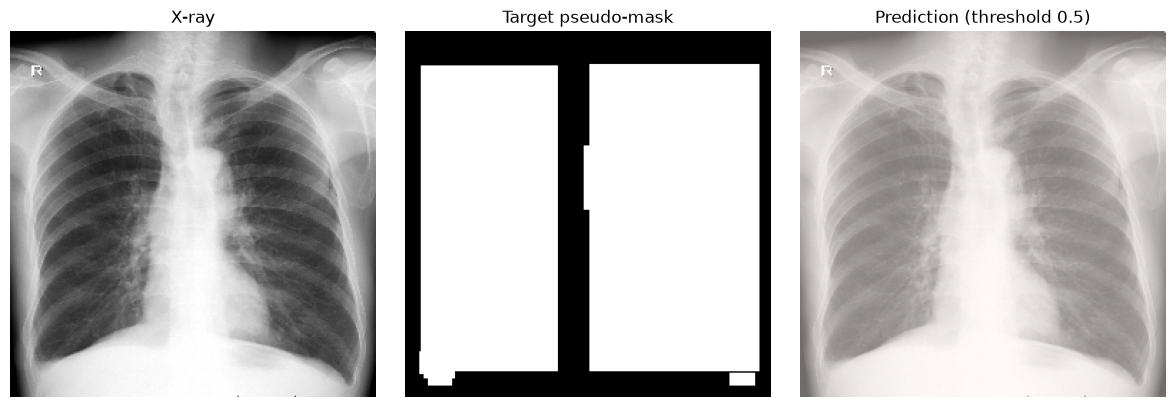

In [10]:
model.eval()
xb, yb = next(iter(val_loader))

with torch.no_grad():
    probabilities = torch.sigmoid(model(xb.to(device))).cpu()

image = xb[0, 0].numpy()
target = yb[0, 0].numpy()
probability_map = probabilities[0, 0].numpy()
predicted_mask = probability_map >= THRESHOLD

print("Probability range:", float(probability_map.min()), "to", float(probability_map.max()))
print("Mean probability:", float(probability_map.mean()))
print("Predicted positive fraction:", float(predicted_mask.mean()))
print("Target positive fraction:", float(target.mean()))

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(image, cmap="gray")
ax[0].set_title("X-ray")
ax[1].imshow(target, cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Target pseudo-mask")
ax[2].imshow(image, cmap="gray")
ax[2].imshow(predicted_mask, cmap="Reds", alpha=0.45)
ax[2].set_title(f"Prediction (threshold {THRESHOLD})")

for axis in ax:
    axis.axis("off")

plt.tight_layout()
plt.show()

## 11. Save the model

The checkpoint stores model weights and the input size. Keep the notebook, manifest, and annotation CSVs with the experiment so the run can be reproduced.

In [11]:
model_path = ROOT / "data" / "processed" / "unet_bbox_pseudomask_baseline.pt"
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_size": SIZE,
        "threshold": THRESHOLD,
        "seed": SEED,
        "target_type": "bounding-box-derived pseudo-mask",
    },
    model_path,
)
print("Model checkpoint saved to:", model_path)

Model checkpoint saved to: c:\Users\johnm\chest-xray-ai-annotation\data\processed\unet_bbox_pseudomask_baseline.pt
